# Loss Balance Analysis: Alpha/Beta vs Losses Ratio

This notebook analyzes how the loss balancing coefficients (alpha, beta) depend on the ratio of EMA losses and the strength parameter.


## Mathematical Formulation

### Step 1: EMA Losses
$$
\text{ema\_loss}_A = \gamma \cdot \text{ema\_loss}_A + (1 - \gamma) \cdot \text{loss}_A
$$
$$
\text{ema\_loss}_B = \gamma \cdot \text{ema\_loss}_B + (1 - \gamma) \cdot \text{loss}_B
$$

where $\gamma$ is the EMA momentum (typically 0.99).

### Step 2: Losses Ratio
$$
r = \frac{\text{ema\_loss}_A}{\text{ema\_loss}_B}
$$

### Step 3: Compute Weights
$$
\text{total} = \text{ema\_loss}_A + \text{ema\_loss}_B
$$
$$
w_A = \left(\frac{\text{ema\_loss}_A}{\text{total}}\right)^s = \left(\frac{r}{r+1}\right)^s
$$
$$
w_B = \left(\frac{\text{ema\_loss}_B}{\text{total}}\right)^s = \left(\frac{1}{r+1}\right)^s
$$

where $s$ is the strength parameter.

### Step 4: Normalize
$$
\text{norm} = w_A + w_B
$$
$$
\alpha = \frac{w_A}{\text{norm}} \times 2
$$
$$
\beta = \frac{w_B}{\text{norm}} \times 2
$$

Note: $\alpha + \beta = 2$ always.

### Step 5: Final Loss
$$
\text{loss} = \alpha \cdot \text{loss}_A + \beta \cdot \text{loss}_B
$$


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Set plot style
plt.style.use('default')
plt.rcParams['figure.figsize'] = (14, 10)
plt.rcParams['font.size'] = 11


In [2]:
def compute_alpha_beta(losses_ratio, strength, clip_min=0.1, clip_max=10.0):
    """
    Compute alpha and beta coefficients given losses_ratio and strength.
    
    Args:
        losses_ratio: ratio of ema_loss_A / ema_loss_B
        strength: balancing strength parameter
        clip_min: minimum value for alpha/beta
        clip_max: maximum value for alpha/beta
    
    Returns:
        alpha, beta: balancing coefficients
    """
    r = losses_ratio
    
    # Compute weights
    weight_A = (r / (r + 1)) ** strength
    weight_B = (1 / (r + 1)) ** strength
    
    # Normalize so alpha + beta = 2
    norm = weight_A + weight_B
    alpha = (weight_A / norm) * 2.0
    beta = (weight_B / norm) * 2.0
    
    # Apply clipping
    alpha = np.clip(alpha, clip_min, clip_max)
    beta = np.clip(beta, clip_min, clip_max)
    
    return alpha, beta


## Visualization: Alpha and Beta vs Losses Ratio

Let's visualize how alpha and beta change with different losses ratios for various strength values.


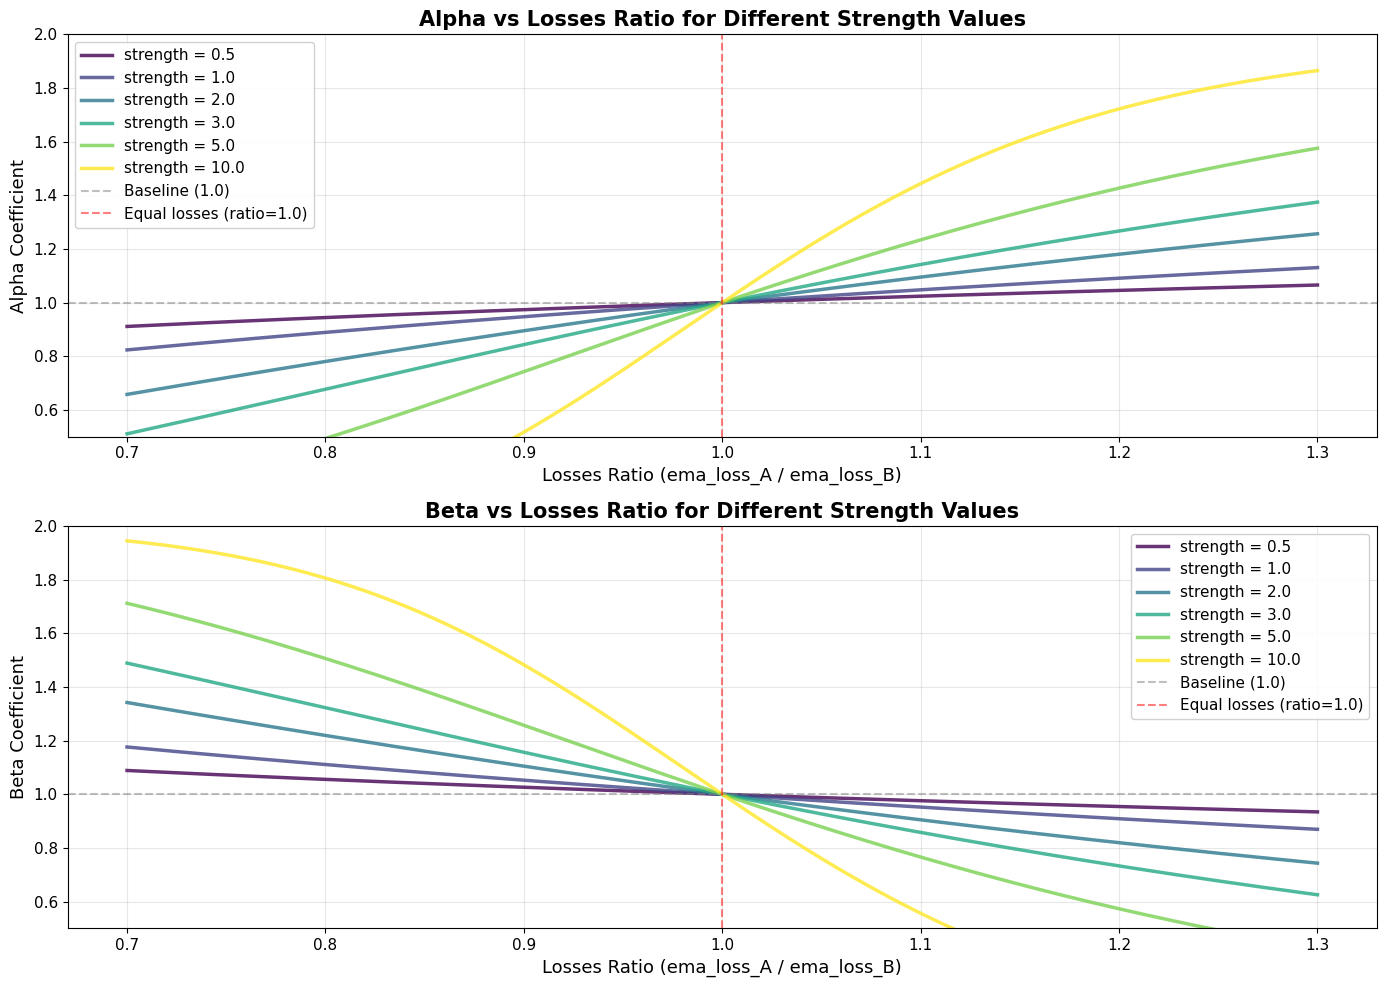


Interpretation:
- When losses_ratio = 1.0: losses are equal, alpha = beta = 1.0
- When losses_ratio > 1.0: loss_A > loss_B, so alpha increases to give more weight to loss_A
- When losses_ratio < 1.0: loss_A < loss_B, so beta increases to give more weight to loss_B
- Higher strength = more aggressive balancing (steeper curves)


In [3]:
# Define losses_ratio range (from 0.7 to 1.3)
# ratio = 1.0 means losses are equal
# ratio > 1.0 means loss_A > loss_B
# ratio < 1.0 means loss_A < loss_B
losses_ratio_range = np.linspace(0.7, 1.3, 1000)

# Define different strength values to compare
strength_values = [0.5, 1.0, 2.0, 3.0, 5.0, 10.0]

# Create figure with 2 subplots
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Colors for different strengths
colors = plt.cm.viridis(np.linspace(0, 1, len(strength_values)))

# Plot Alpha
ax1 = axes[0]
for i, strength in enumerate(strength_values):
    alphas = []
    for ratio in losses_ratio_range:
        alpha, _ = compute_alpha_beta(ratio, strength)
        alphas.append(alpha)
    
    ax1.plot(losses_ratio_range, alphas, 
             label=f'strength = {strength}', 
             color=colors[i], 
             linewidth=2.5,
             alpha=0.8)

ax1.axhline(y=1.0, color='gray', linestyle='--', linewidth=1.5, alpha=0.5, label='Baseline (1.0)')
ax1.axvline(x=1.0, color='red', linestyle='--', linewidth=1.5, alpha=0.5, label='Equal losses (ratio=1.0)')
ax1.set_xlabel('Losses Ratio (ema_loss_A / ema_loss_B)', fontsize=13)
ax1.set_ylabel('Alpha Coefficient', fontsize=13)
ax1.set_title('Alpha vs Losses Ratio for Different Strength Values', fontsize=15, fontweight='bold')
ax1.legend(loc='upper left', framealpha=0.9, fontsize=11)
ax1.grid(True, alpha=0.3)
ax1.set_ylim(0.5, 2.0)

# Plot Beta
ax2 = axes[1]
for i, strength in enumerate(strength_values):
    betas = []
    for ratio in losses_ratio_range:
        _, beta = compute_alpha_beta(ratio, strength)
        betas.append(beta)
    
    ax2.plot(losses_ratio_range, betas, 
             label=f'strength = {strength}', 
             color=colors[i], 
             linewidth=2.5,
             alpha=0.8)

ax2.axhline(y=1.0, color='gray', linestyle='--', linewidth=1.5, alpha=0.5, label='Baseline (1.0)')
ax2.axvline(x=1.0, color='red', linestyle='--', linewidth=1.5, alpha=0.5, label='Equal losses (ratio=1.0)')
ax2.set_xlabel('Losses Ratio (ema_loss_A / ema_loss_B)', fontsize=13)
ax2.set_ylabel('Beta Coefficient', fontsize=13)
ax2.set_title('Beta vs Losses Ratio for Different Strength Values', fontsize=15, fontweight='bold')
ax2.legend(loc='upper right', framealpha=0.9, fontsize=11)
ax2.grid(True, alpha=0.3)
ax2.set_ylim(0.5, 2.0)

plt.tight_layout()
plt.show()

print("\nInterpretation:")
print("- When losses_ratio = 1.0: losses are equal, alpha = beta = 1.0")
print("- When losses_ratio > 1.0: loss_A > loss_B, so alpha increases to give more weight to loss_A")
print("- When losses_ratio < 1.0: loss_A < loss_B, so beta increases to give more weight to loss_B")
print("- Higher strength = more aggressive balancing (steeper curves)")


## Alpha/Beta Ratio Analysis

Lets also look at the ratio alpha/beta compared to the losses ratio.


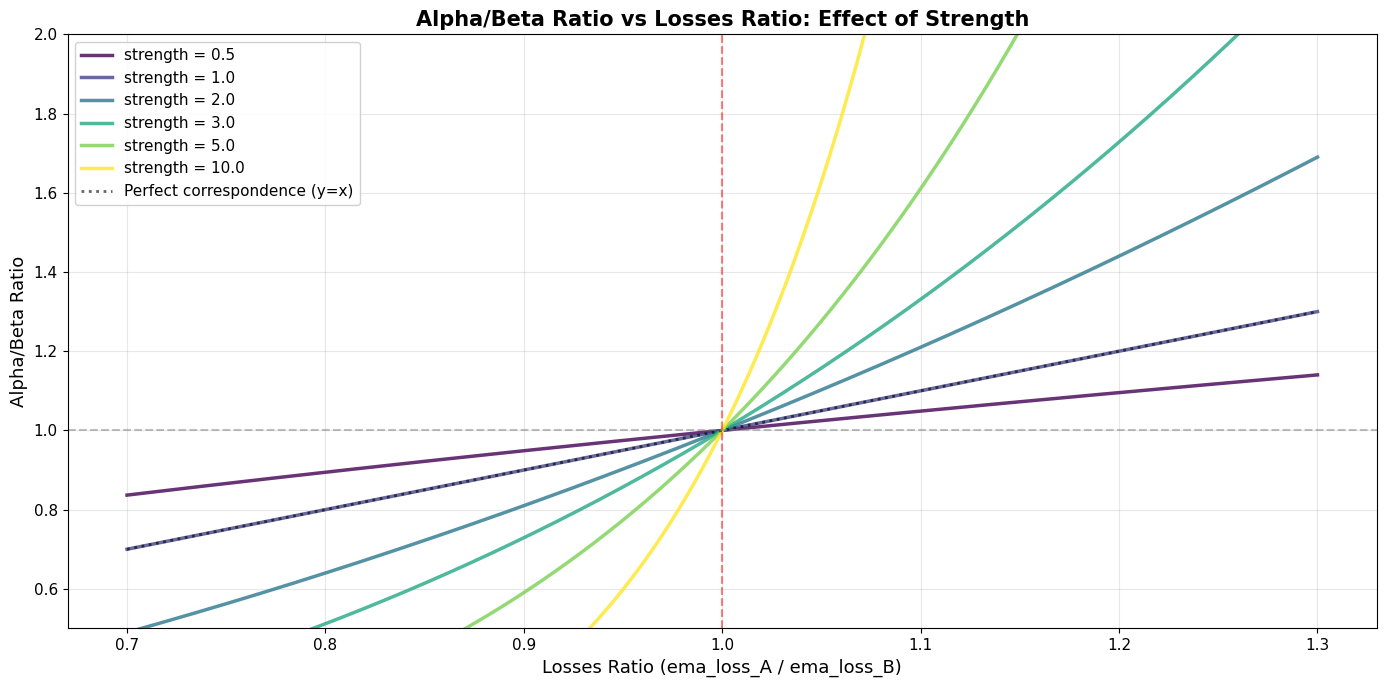


Key Observations:
- The black dotted line (y=x) shows perfect correspondence between losses_ratio and alpha/beta ratio
- Higher strength values amplify the effect of losses_ratio on alpha/beta ratio
- For strength=1.0, the curve is close to y=x
- For strength=5.0 or higher, even small differences in losses create large differences in alpha/beta


In [4]:
fig, ax = plt.subplots(figsize=(14, 7))

# Plot alpha/beta ratio
for i, strength in enumerate(strength_values):
    ratios = []
    for loss_ratio in losses_ratio_range:
        alpha, beta = compute_alpha_beta(loss_ratio, strength)
        ratios.append(alpha / beta if beta > 0 else 0)
    
    ax.plot(losses_ratio_range, ratios, 
            label=f'strength = {strength}', 
            color=colors[i], 
            linewidth=2.5,
            alpha=0.8)

# Plot y=x line (what would happen with strength=1 in linear space)
ax.plot(losses_ratio_range, losses_ratio_range, 
        color='black', 
        linestyle=':', 
        linewidth=2,
        label='Perfect correspondence (y=x)',
        alpha=0.6)

ax.axhline(y=1.0, color='gray', linestyle='--', linewidth=1.5, alpha=0.5)
ax.axvline(x=1.0, color='red', linestyle='--', linewidth=1.5, alpha=0.5)
ax.set_xlabel('Losses Ratio (ema_loss_A / ema_loss_B)', fontsize=13)
ax.set_ylabel('Alpha/Beta Ratio', fontsize=13)
ax.set_title('Alpha/Beta Ratio vs Losses Ratio: Effect of Strength', fontsize=15, fontweight='bold')
ax.legend(loc='upper left', framealpha=0.9, fontsize=11)
ax.grid(True, alpha=0.3)
ax.set_ylim(0.5, 2.0)

plt.tight_layout()
plt.show()

print("\nKey Observations:")
print("- The black dotted line (y=x) shows perfect correspondence between losses_ratio and alpha/beta ratio")
print("- Higher strength values amplify the effect of losses_ratio on alpha/beta ratio")
print("- For strength=1.0, the curve is close to y=x")
print("- For strength=5.0 or higher, even small differences in losses create large differences in alpha/beta")


## Numerical Examples

Lets compute specific examples to see the effect of different strength values.


In [5]:
import pandas as pd

# Example scenarios
example_ratios = [0.8, 0.9, 1.0, 1.1, 1.2]

# Create table
results = []
for ratio in example_ratios:
    row = {'losses_ratio': ratio}
    for strength in strength_values:
        alpha, beta = compute_alpha_beta(ratio, strength)
        row[f'alpha (s={strength})'] = alpha
        row[f'beta (s={strength})'] = beta
        row[f'a/b (s={strength})'] = alpha / beta if beta > 0 else 0
    results.append(row)

df = pd.DataFrame(results)

# Display alpha values
print("\n" + "="*80)
print("ALPHA COEFFICIENTS")
print("="*80)
alpha_cols = ['losses_ratio'] + [col for col in df.columns if col.startswith('alpha')]
print(df[alpha_cols].to_string(index=False))

# Display beta values
print("\n" + "="*80)
print("BETA COEFFICIENTS")
print("="*80)
beta_cols = ['losses_ratio'] + [col for col in df.columns if col.startswith('beta')]
print(df[beta_cols].to_string(index=False))

# Display alpha/beta ratios
print("\n" + "="*80)
print("ALPHA/BETA RATIOS")
print("="*80)
ratio_cols = ['losses_ratio'] + [col for col in df.columns if col.startswith('a/b')]
print(df[ratio_cols].to_string(index=False))



ALPHA COEFFICIENTS
 losses_ratio  alpha (s=0.5)  alpha (s=1.0)  alpha (s=2.0)  alpha (s=3.0)  alpha (s=5.0)  alpha (s=10.0)
          0.8       0.944272       0.888889       0.780488       0.677249       0.493613        0.193926
          0.9       0.973666       0.947368       0.895028       0.843262       0.742526        0.517067
          1.0       1.000000       1.000000       1.000000       1.000000       1.000000        1.000000
          1.1       1.023823       1.047619       1.095023       1.141999       1.233866        1.443477
          1.2       1.045549       1.090909       1.180328       1.266862       1.426658        1.721903

BETA COEFFICIENTS
 losses_ratio  beta (s=0.5)  beta (s=1.0)  beta (s=2.0)  beta (s=3.0)  beta (s=5.0)  beta (s=10.0)
          0.8      1.055728      1.111111      1.219512      1.322751      1.506387       1.806074
          0.9      1.026334      1.052632      1.104972      1.156738      1.257474       1.482933
          1.0      1.000000      1

## Interpretation Guide

### When to use different strength values:

- **strength = 0.5-1.0**: Gentle balancing
  - Use when you want minimal intervention
  - Good when losses naturally stay balanced

- **strength = 2.0**: Moderate balancing (DEFAULT)
  - Reasonable default for most cases
  - Noticeable but not aggressive correction

- **strength = 3.0-5.0**: Aggressive balancing
  - Use when one stream consistently has higher loss
  - Strong corrective action
  - Risk: may oscillate if losses fluctuate

- **strength = 10.0+**: Very aggressive
  - Extreme cases only
  - May cause training instability
  - Consider using lower strength with adjusted clip_min/clip_max instead

### Remember:
- Alpha and beta depend **only** on the ratio of losses, not absolute values
- alpha + beta = 2 always (normalized)
- Higher loss gets higher coefficient which means stronger gradient signal for that stream
